# 11 · Drivers within wards and the 2015 earthquake
Standardised logistic coefficients pooled vs with ward fixed effects (`src/drivers_analysis.py`); USGS ShakeMap
exposure, quintiles and adjusted models; cause-specific predictability (`src/spatial_analysis.py`, `src/descriptive.py`).

In [1]:
import sys, os, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)
M, F = ROOT / "results/metrics", ROOT / "results/figures"
def table(name, **kw):
    t = pd.read_csv(M / name, **kw)
    return t.round(4)
def fig(name, width=1100):
    display(Image(filename=str(F / name), width=width))

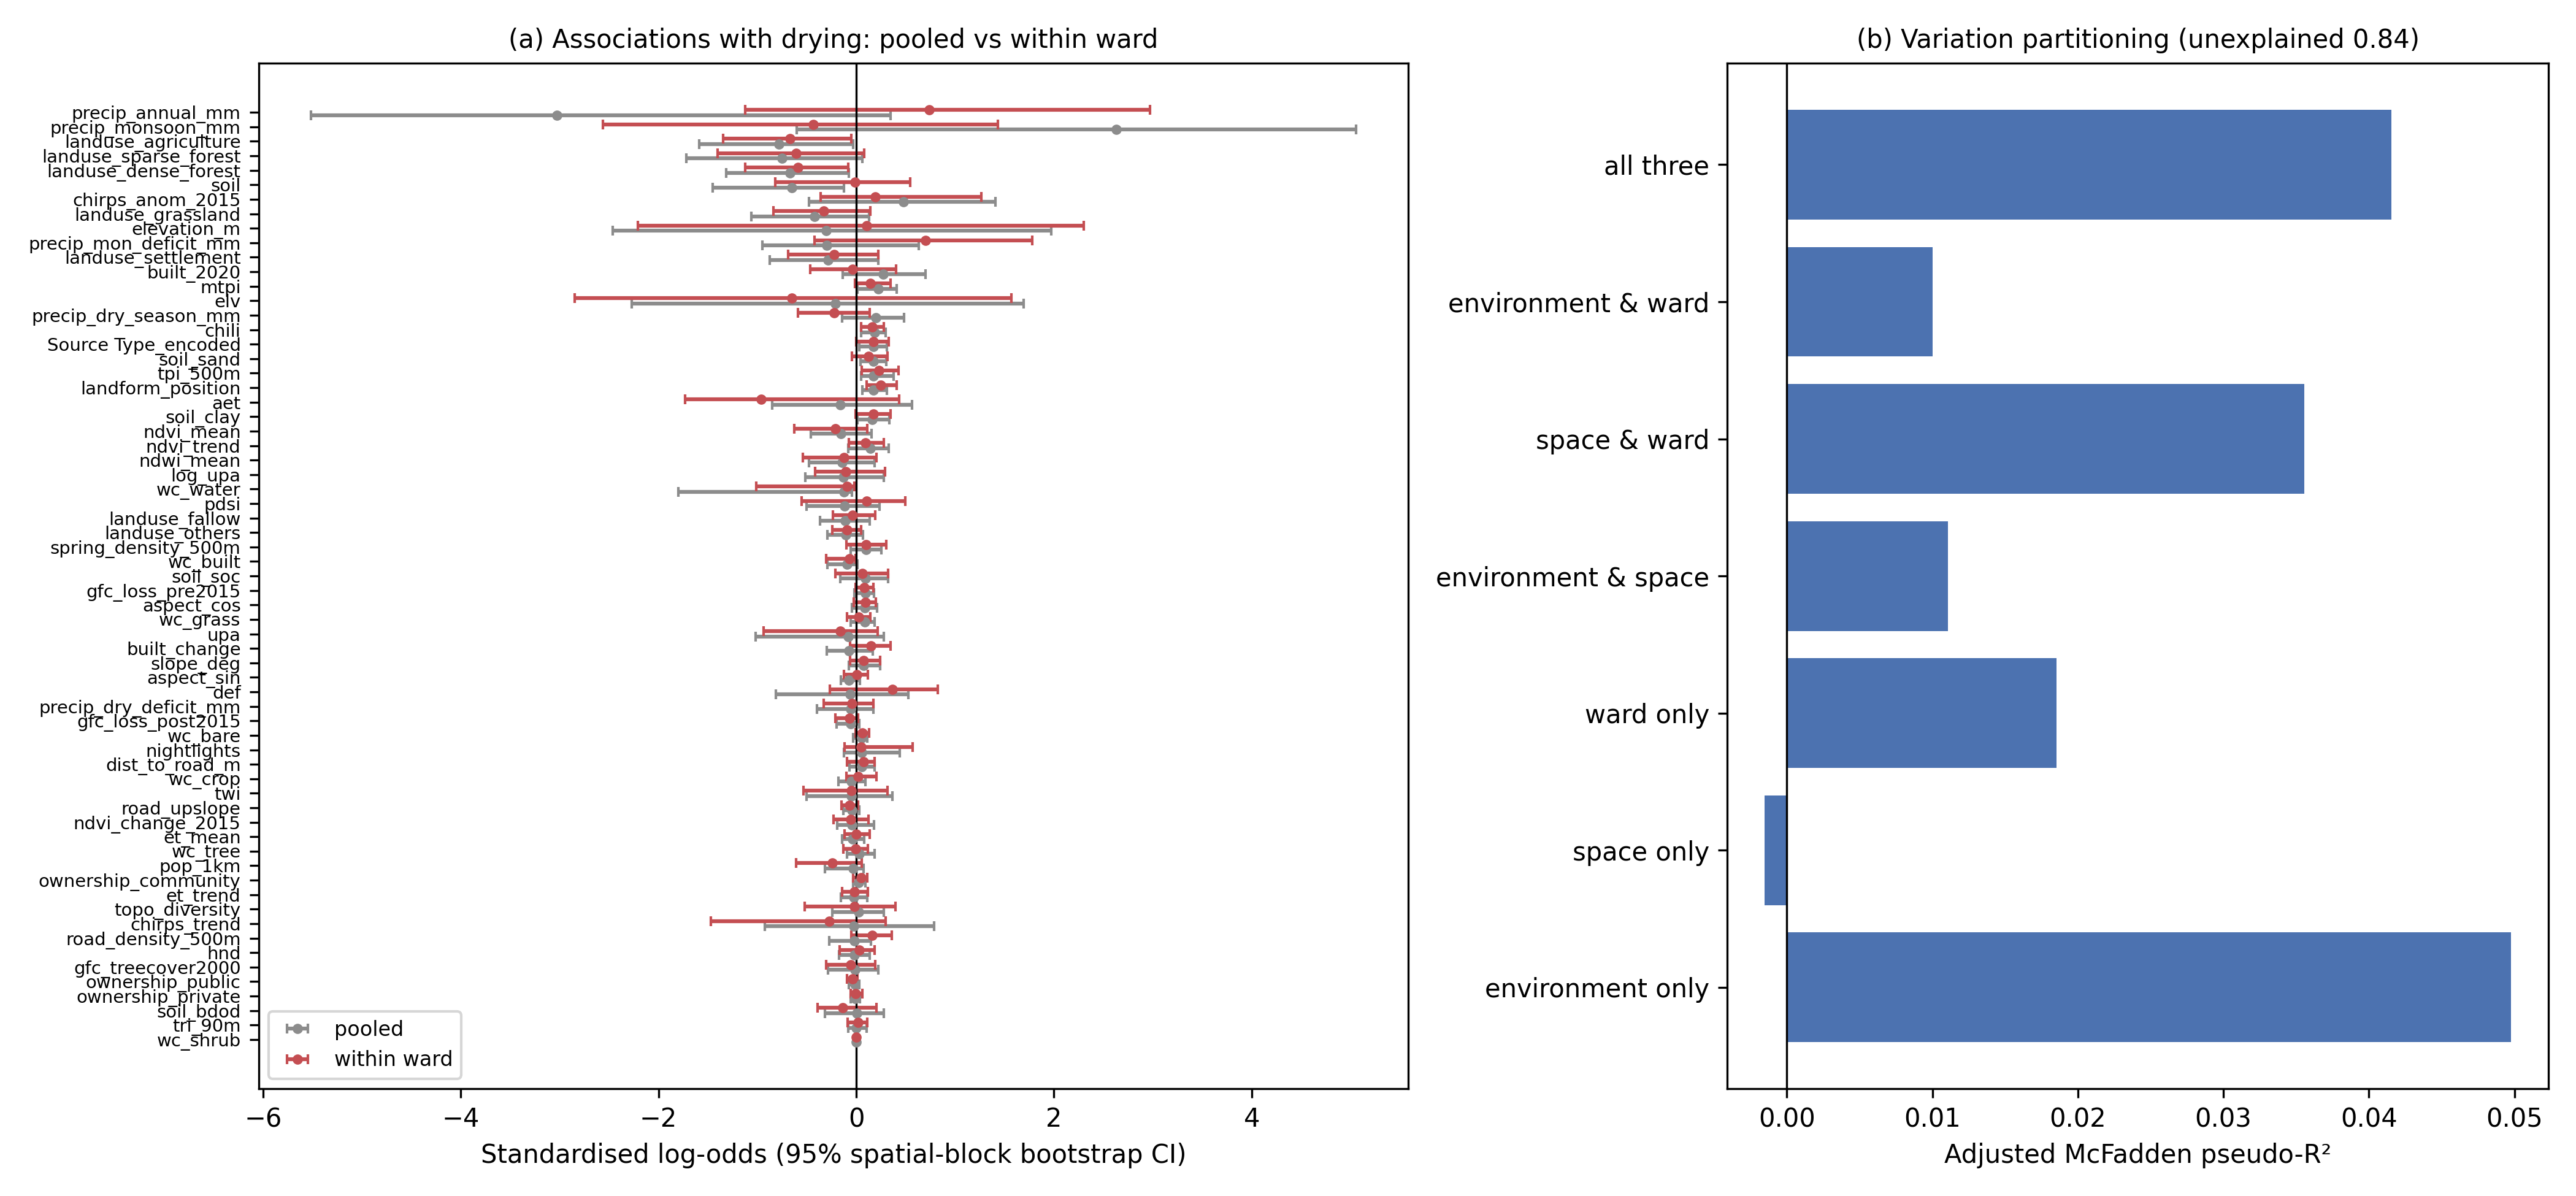

In [2]:
fig("dr_drivers.png")

In [3]:
d = table("dr_pooled_vs_within_ward.csv")
d.pivot_table(index="term", columns="model", values=["coef_per_sd", "ci_low", "ci_high"]).round(2)

ci_high                                  ci_low                                  coef_per_sd                                 
model                pooled within ward (ward fixed effects) pooled within ward (ward fixed effects)      pooled within ward (ward fixed effects)
term                                                                                                                                             
Source Type_encoded    0.31                             0.33   0.03                            -0.00        0.18                             0.17
aet                    0.56                             0.43  -0.85                            -1.73       -0.16                            -0.96
aspect_cos             0.21                             0.20  -0.05                            -0.03        0.09                             0.09
aspect_sin             0.04                             0.11  -0.16                            -0.12       -0.07                             0.01
built_2020             0.70                             0.40  -0.14                            -0.46        0.27                            -0.04
...                     ...                              ...    ...                              ...         ...                              ...
wc_crop                0.09                             0.20  -0.18                            -0.10       -0.05                             0.02
wc_grass               0.18                             0.14  -0.06                            -0.09        0.08                             0.03
wc_shrub               0.00                             0.00   0.00                             0.00        0.00                             0.00
wc_tree                0.18                             0.12  -0.09                            -0.13        0.03                            -0.01
wc_water              -0.04                            -0.02  -1.80                            -1.01       -0.12                            -0.09

[65 rows x 6 columns]

## Earthquake exposure

In [4]:
display(table("sa_seismic_quintiles.csv")); display(table("sa_seismic_logit.csv")); table("cause_specific_auc.csv")

,q,lo,hi,n,rate,variable
0,0,42.4384,52.2698,1138,0.1424,pga_main
1,1,52.2764,56.0771,1138,0.2627,pga_main
2,2,56.0818,59.5544,1137,0.2823,pga_main
3,3,59.5589,62.5014,1138,0.3181,pga_main
4,4,62.5038,71.2753,1138,0.3313,pga_main
5,0,12.2242,19.7137,1138,0.1344,pga_may12
6,1,19.7165,21.9612,1138,0.2232,pga_may12
7,2,21.9613,23.7754,1137,0.2858,pga_may12
8,3,23.7761,26.0654,1138,0.3163,pga_may12
9,4,26.0671,35.8420,1138,0.3770,pga_may12


,term,coef_per_sd,ci_low,ci_high,odds_ratio_per_sd,ci_excludes_zero,model
0,pga_main,0.2096,-0.1355,0.4632,1.2331,False,drying ~ seismic
1,pga_may12,0.1655,-0.1204,0.5632,1.1799,False,drying ~ seismic
2,aftershocks_20km,0.1686,-0.1899,0.4536,1.1837,False,drying ~ seismic
3,pga_main,-0.2307,-0.6433,0.1051,0.7940,False,drying ~ seismic + environment (no lat/lon)
4,pga_may12,0.6810,0.2527,0.9979,1.9759,True,drying ~ seismic + environment (no lat/lon)
5,aftershocks_20km,-0.2558,-0.5915,0.1149,0.7743,False,drying ~ seismic + environment (no lat/lon)
6,pga_main,0.1632,-0.2094,0.4728,1.1773,False,earthquake-attributed | dried
7,pga_may12,0.0610,-0.4873,0.4575,1.0629,False,earthquake-attributed | dried
8,aftershocks_20km,-0.1463,-0.4626,0.1653,0.8639,False,earthquake-attributed | dried
9,pga_main,-0.0091,-0.4186,0.2821,0.9909,False,dried in 2072 BS | dried


,model,dried_subset,n_dried,n_active,roc_auc,ci_low,ci_high
0,Logistic Regression,all dried,1521,4168,0.6909,0.6752,0.7060
1,Logistic Regression,earthquake-attributed,521,4168,0.6495,0.6235,0.6744
2,Logistic Regression,other causes,1000,4168,0.7125,0.6959,0.7301
3,HydroBoost-GAT,all dried,1521,4168,0.7051,0.6893,0.7201
4,HydroBoost-GAT,earthquake-attributed,521,4168,0.6664,0.6411,0.6919
5,HydroBoost-GAT,other causes,1000,4168,0.7252,0.7080,0.7420
6,CatBoost,all dried,1521,4168,0.7015,0.6862,0.7167
7,CatBoost,earthquake-attributed,521,4168,0.6779,0.6542,0.7023
8,CatBoost,other causes,1000,4168,0.7138,0.6951,0.7306
